# Conditional diffusion models

### Simple examples of conditional diffusion models

Once the framework for unconditional diffusion model is there, the general idea of conditional diffusion model is surprisingly simple

In this notebook, built on the previous notebook diffusion_intro.ipynb, we examine how to build a simple conditional diffusion model.

It will have a performance issue which is exposed here, and addressed in the next notebook. 

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from funs.SineWave_Dataset import SineWave_Random_DataSet
from funs.plotting import plot_batched_lines
from funs.scheduler import (
    add_noise_from_zero,
    add_noise_onestep_cum_sampler,
    ddpm_sampler,
    noise_scheduler,
)
from funs.time_embedding import get_sinusoidal_table
from funs.unet_1d import UNet1D

torch.manual_seed(7)
plt.rcParams["figure.figsize"] = (5, 3)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: cuda


## A slightly more complicated dataset

Instead of SineWave_DataSet previously, we work with SineWave_Random_DataSet in this notebook. For each sample, it outputs the frequency and a curve that is a sine wave.

It also outputs a phase and a bias (the 3rd and 4th outputs). Both are always returned and are always random numbers, but they are only *applied* to the curve when the matching switch is on:

````python
random_phase = True   # the sine wave is shifted along x by the returned phase
random_bias = True    # the returned bias is added to the whole curve (an up/down offset)
````

In this notebook, we set
````python
random_bias = True
random_phase = False
````
So every curve gets a random up/down offset, but no phase shift: every curve starts at its offset at the left end and goes up. The returned phase is a random number that was **not** used. We do not need either value (offset and phase) for training, so the training loop below ignores both.

The idea is that the generated curves have something deterministic, i.e., the frequency of the sine wave, and some stochasticity, i.e., the random offset. 

Let's have a look at a few samples

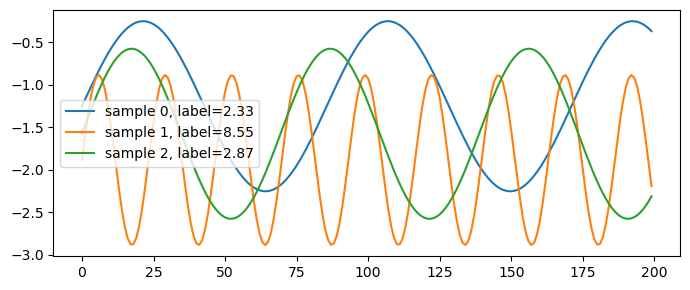

condition batch: (64, 1)
signal batch:    (64, 200)
Adopting a linear scheduler


In [8]:
freq_max = 10

dataset = SineWave_Random_DataSet(freq_max=freq_max, n_dim=200, random_bias = True, random_phase=False)
data_loader = DataLoader(dataset, batch_size=64, shuffle=True)

conditions, clean_batch, _, _ = next(iter(data_loader))
plot_batched_lines(
    clean_batch[:],
    conditions[:],
    max_lines=3,
    figsize=(7, 3),
)

print("condition batch:", tuple(conditions.shape))
print("signal batch:   ", tuple(clean_batch.shape))

T = 500
schedule = noise_scheduler(T=T)

## Conditional diffusion model

In unconditional diffusion model, during training, for each sample, we are given :
- The sample $x_0$
- The generated noise 
- The noisy sample $x_t$, which is from the two above
  
Our goal is to estimate the noise given $x_t$ and the time step $t$

In conditional diffusion model, we are given the sample and their corresponding condition $c$. What's next? 

- Generate $x_t$: this step is identical to how it is done in unconditional diffusion model. No condition ($c$) involved
- The training goal is to estimate the generated noise as well. In **conditional** diffusion model, we estimate the generated noise given $x_t$, time step $t$, and the condition $c$


During sample generation, we follow the same procedure as done in unconditional diffusion except that we use the noise predictor that is based on $x_t$, $t$, and the conditioning. 


These are the differences between unconditional diffusion model and **direct** conditional model



## Direct conditioning is one of several ways to condition a diffusion model

Two alternatives, not covered here:

- **Classifier-free guidance** builds directly on the direct conditional model above. Train the same
  $\epsilon_\theta(x_t,t,c)$, but swap $c$ for a null token $\varnothing$ on a
  fraction of training steps so one network learns both the conditional and the
  unconditional score; at sampling, extrapolate between them. 

- **Classifier guidance** builds on the *unconditional* model instead. Keep
  $\epsilon_\theta(x_t,t)$ frozen, train a separate classifier $p_\phi(c\mid x_t)$
  on noisy inputs, and add $s\,\nabla_{x_t}\log p_\phi(c\mid x_t)$ to the score at
  sampling time (this is related to the score matching perspectives of the diffusion model, which is not covered in this tutorial). No conditional denoiser is trained.


We refer to **direct** conditioning diffusion model as conditioning diffusion model for simplicity in the rest of the notebook.


## How to inject the condition into the denoiser $\epsilon_\theta(x_t, t, c)$

The mechanism follows from the *shape* of $c$.

**Start from $t$.** The timestep is itself a condition, and every diffusion network
already has a pathway for it: sinusoidal embedding → MLP → injected into every
residual block. A global $c$ can reuse that pathway unchanged.

### Global condition — class label, low-dimensional parameter vector, pooled text embedding

Embed $c$, then either

- **add** it to the timestep embedding, $e = \mathrm{MLP}(e_t)+\mathrm{MLP}(e_c)$, and
  inject as usual — simplest, no new machinery; or
- **modulate** (FiLM / AdaGN / adaLN): predict per-channel scale and shift from $e$,
  $$h \leftarrow \gamma(e)\odot\mathrm{Norm}(h)+\beta(e)$$
  Strictly more expressive — addition is the special case $\gamma\equiv 1$ — and the
  standard choice (ADM, DiT).

Either way the embedding enters *hidden features*, never $x_t$ itself.

### Spatially aligned condition — segmentation or depth map, low-res image, another field on the same grid

**Concatenate along channels at the input**, $[\,x_t\,;\,c\,]$, widening the first
convolution. This works precisely *because* position $i$ of $c$ corresponds to
position $i$ of $x_t$, so the convolution can exploit the alignment. Resample if
resolutions differ. Broadcasting a global vector across all positions and
concatenating also works, but wastes capacity.

### Variable-length or set-structured condition — text tokens, a sequence of observations

**Cross-attention**: queries from image features, keys and values from $c$'s tokens.
Handles arbitrary $|c|$ and lets different spatial locations attend to different
parts of the condition. Cost $O(HW\cdot L_c)$.


## Our specific model
### How the embedding information enters the neural network
Our neural network used in the previous notebook can work with both conditional and unconditional diffusion model. 
At Line 178 in `unet_1d.py`, the conditioning enters the neural network via the line

````python
emb = self.cond_embed(t, cond)
````
Here t is the time step for sinusoidal embedding introduced in the previous notebook. How cond_emb works will be examined later. 

The emb here contains the embedded information of the time step and cond (the conditioning). 
It is used as input in various places throughout the forward model. They are all cases of the class ResBlock1D_conditional. Within it (lines 97 and 108):
````python
self.emb_proj = nn.Linear(emb_dim, out_ch)
h = h + self.emb_proj(emb).unsqueeze(-1)
````
The emb is first projected to the dim of the output channel (for the `ResBlock1D_conditional` block, not the output of the model), and then added to h. 

### How the time step and conditioning are put to gether (i.e., what does cond_embed do)
We can examine `ConditionEmbedding`, which is the class of the case `cond_embed` (lines 58-68 in unet_1d.py):
````python
if cond is not None:
    if cond.ndim == 1:
        cond = cond.unsqueeze(-1)
    c_emb = self.cond_proj(cond.float())
    
    return t_emb + c_emb

else:
    return t_emb
````
Namely, if cond is None, we simply ignore it, and the conditioning is solely time step


Lines 63-68:
````python
c_emb = self.cond_proj(cond.float())
return t_emb + c_emb
````
where
````python
self.cond_proj = nn.Sequential(
    nn.Linear(cond_dim, out_dim),
    nn.SiLU(),
    nn.Linear(out_dim, out_dim),
)
````
This is similarly to how time is embedded. In summary, time and condition are projected to the same dimension, and then add together to get the `emb` in line 178 of unet_1d.py


Now let's try it. The cell below has an additional argument compared to the case with unconditional diffusion model, which is `dummy_c`

## Let's specify the model and check its output
The model structure is similar to what we used in the diffusion_intro notebook

In [9]:
model = UNet1D(
    in_channels=1,
    base_channels=64,
    t_steps=500,
    t_dim=64,
    cond_dim=1,
    emb_dim=72,
)

dummy_x_t = torch.randn(12, 1, 200)
dummy_t = torch.randint(0, T, (12,))
dummy_c = torch.randn(12, 1)

model.eval()
with torch.no_grad():
    dummy_prediction = model(dummy_x_t, dummy_t, dummy_c)
    
assert dummy_prediction.shape == dummy_x_t.shape
print("model input: ", tuple(dummy_x_t.shape))
print("model output:", tuple(dummy_prediction.shape))



model input:  (12, 1, 200)
model output: (12, 1, 200)


## Training
We only need to make a few changes in the cell below compared to the one in the unconditional diffusion model intro (`diffusion_intro.ipynb`):


From:
````python
for batch_index, (_, x_clean_batch) in enumerate(data_loader):
````
To:
````python
for batch_index, (x_label_batch, x_clean_batch, _, _) in enumerate(data_loader):
````
We now keep the frequency (`x_label_batch`) instead of throwing it away. SineWave_Random_DataSet returns 4 values, so the phase and the bias are unpacked into `_` and ignored.


Add:
````python
x_label_batch = x_label_batch.to(device)
x_label_batch = x_label_batch/freq_max
````
The first line moves the conditioning to the same device as the model. The second normalizes the frequency by freq_max, so that the conditioning stays between 0 and 1. The same normalization must be applied when we generate samples later (note the `/freq_max` in the generation cell). This does not represent best practice, and is adopted here in an ad-hoc way. We do not recommend this style.


From:
````python
predicted_noise = model(x_t_batch, t_batch, None)
````
To:
````python
predicted_noise = model(x_t_batch, t_batch, x_label_batch)
````

In [10]:
TRAIN_MODEL = True
EPOCHS = 100
weights_path = Path("trained_parameters/conditional_unet.pt")

model = model.to(device)
schedule_device = {name: values.to(device) for name, values in schedule.items()}

if TRAIN_MODEL:
    loss_fn = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=5e-4)
    model.train()

    for epoch_index in range(EPOCHS):
        running_loss = 0.0

        for batch_index, (x_label_batch, x_clean_batch, _, _) in enumerate(data_loader):
            x_clean_batch = x_clean_batch.to(device)
            x_label_batch = x_label_batch.to(device)
            x_label_batch = x_label_batch/freq_max  ### Normalization is lazily done here
            t_batch = torch.randint(
                0,
                T,
                (x_clean_batch.shape[0],),
                device=device,
            )

            x_t_batch, target_noise = add_noise_from_zero(
                x_clean_batch,
                t_batch,
                schedule_device,
                device,
            )
            x_t_batch = x_t_batch.unsqueeze(1)
            target_noise = target_noise.unsqueeze(1)

            optimizer.zero_grad()
            predicted_noise = model(x_t_batch, t_batch, x_label_batch)
            loss = loss_fn(predicted_noise, target_noise)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        mean_loss = running_loss / len(data_loader)
        print(f"epoch {epoch_index + 1:02d}: mean loss={mean_loss:.6f}")

    torch.save(model.state_dict(), weights_path)

else:
    state_dict = torch.load(weights_path, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)
    print(f"Loaded pretrained weights from {weights_path}.")

model.eval()

epoch 01: mean loss=0.112321
epoch 02: mean loss=0.047026
epoch 03: mean loss=0.037062
epoch 04: mean loss=0.031699
epoch 05: mean loss=0.030544
epoch 06: mean loss=0.028093
epoch 07: mean loss=0.026861
epoch 08: mean loss=0.026254
epoch 09: mean loss=0.026702
epoch 10: mean loss=0.025487
epoch 11: mean loss=0.024609
epoch 12: mean loss=0.024928
epoch 13: mean loss=0.023981
epoch 14: mean loss=0.024426
epoch 15: mean loss=0.023581
epoch 16: mean loss=0.023119
epoch 17: mean loss=0.023115
epoch 18: mean loss=0.022987
epoch 19: mean loss=0.022907
epoch 20: mean loss=0.022535
epoch 21: mean loss=0.022618
epoch 22: mean loss=0.022624
epoch 23: mean loss=0.022259
epoch 24: mean loss=0.022078
epoch 25: mean loss=0.021971
epoch 26: mean loss=0.021760
epoch 27: mean loss=0.022321
epoch 28: mean loss=0.021639
epoch 29: mean loss=0.021716
epoch 30: mean loss=0.021511
epoch 31: mean loss=0.022121
epoch 32: mean loss=0.021574
epoch 33: mean loss=0.021056
epoch 34: mean loss=0.021182
epoch 35: mean

UNet1D(
  (cond_embed): ConditionEmbedding(
    (time_proj): Sequential(
      (0): Linear(in_features=64, out_features=72, bias=True)
      (1): SiLU()
      (2): Linear(in_features=72, out_features=72, bias=True)
    )
    (cond_proj): Sequential(
      (0): Linear(in_features=1, out_features=72, bias=True)
      (1): SiLU()
      (2): Linear(in_features=72, out_features=72, bias=True)
    )
  )
  (in_conv): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (down1): ResBlock1D_conditional(
    (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
    (act): SiLU()
    (emb_proj): Linear(in_features=72, out_features=64, bias=True)
    (skip): Identity()
  )
  (pool1): Conv1d(64, 128, kernel_size=(4,), stride=(2,), padding=(1,))
  (down2): ResBlock1D_conditional(
    (conv1): Conv1d

## Generation
Generating the samples are relatively easy. The update from $x_t$ to $x_{t-1}$ is driven by the noise prediction based on $x_t$, $t$, and the condition instead of just $x_t$ and $t$ in unconditional diffusion model. Everything else is the same.

Now that we are done training the method, let's generate and examine a few samples. 

We specify 9 frequencies, i.e., 1.0, 1.5, 2.0, 4.0, 6.0, 7.5, 9.0, 12.0, 16.0. These frequencies act as conditions here, and for each freq/condition, we generate 4 samples and plot them. 

It is worth noting that the dataset's frequency limit is 10, defined by the variable **freq_max**. Including 12.0 and 16.0 here helps us check how the method behaves when extrapolation is needed. 

We also plot the ''real'' sine curve with the correct frequency here for comparison, plotted as thick black lines below. We do not add additional bias to the ''real'' sine curve so they center around 0.


In [11]:
torch.manual_seed(26)

freqs = [1.0, 1.5, 2.0, 4.0, 6.0, 7.5, 9.0, 12.0, 16.0]
generated_list = []
truth_list = []

coord = torch.linspace(0, 2 * torch.pi,  200)

for freq in freqs:
    generated_list.append(
        ddpm_sampler(sample_dim=200, n_sample=4, noise_dict=schedule_device,
            cond = (torch.tensor([freq, freq, freq, freq])/freq_max).to(device),
    model=model,
    device=device,
        )
    )
    
    truth_list.append(torch.sin(coord * freq))

Looking at the results below, it is hard to make direct comparisons because they have different biases.

However, it can be seen that when the freqeuncy (condition) is lower, the generated curves are not always looking like a sine wave



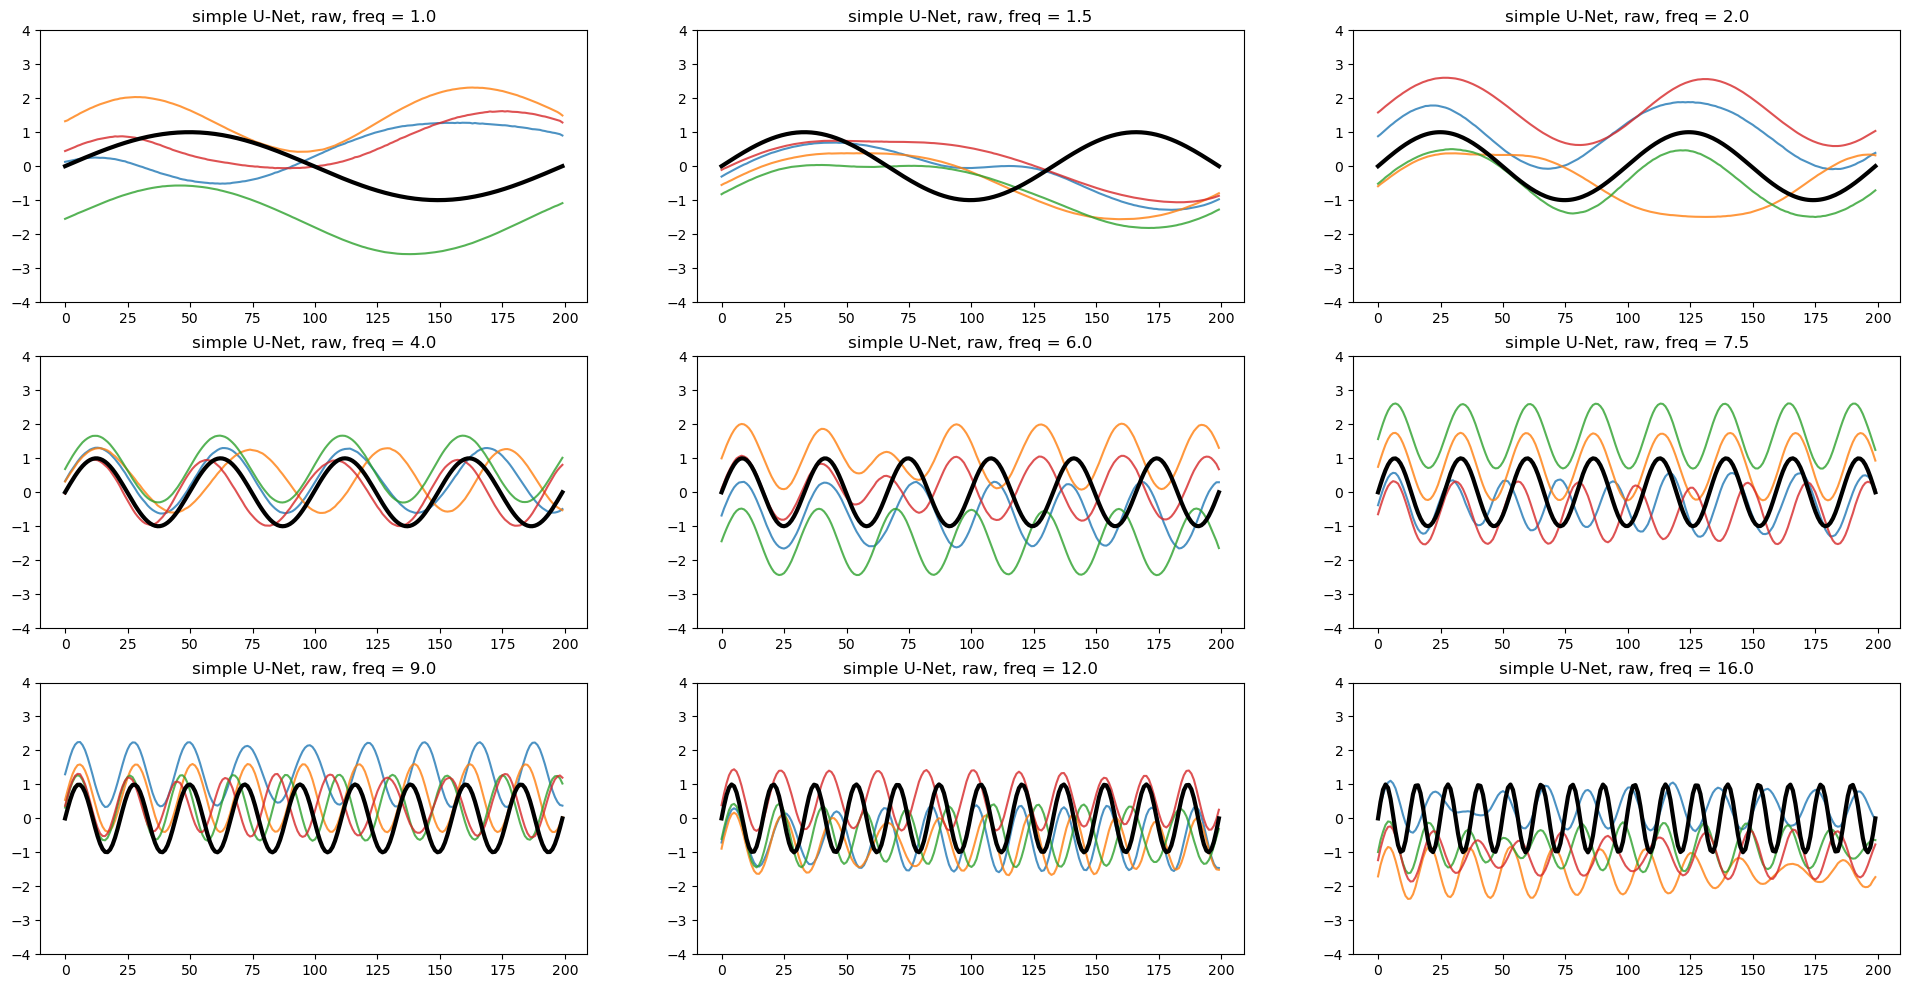

In [13]:
fig, axs = plt.subplots(3, 3, figsize=(24, 12))
axs = axs.ravel()

for ax, generated, truth, freq in zip(axs, generated_list, truth_list, freqs):
    for sample in generated:
        ax.plot(sample[0].detach().cpu(), alpha = 0.8)

    ax.plot(truth, linewidth=3, color = "black")
    ax.set_title(f"simple U-Net, raw, freq = {freq}")
    ax.set_ylim(-4, 4)

Below we shift the generated curves by their mean so that we can compare them with a real sine wave. Their differences are plotted below as well (last fig).

It can be seen that the method does not really perform that well:

- **Low frequencies (1.0–2.0):** most curves look like sine waves, but often with the wrong frequency, and a few are distorted (for example, part of a curve flattens out).
- **Higher frequencies (4.0–9.0):** the curves start in step with the true wave at the left end, but the phase shift grows as x increases, and different curves drift by different amounts.
- **Beyond the training range (12.0 and 16.0):** the generated waves no longer follow the requested frequency, and their amplitude is smaller than 1 (most clearly at 16.0).

One detail that is *not* the model's fault: at frequency 1.5, part of the difference is a flat offset of about −0.2. Centering makes each generated curve average to 0, but 1.5 cycles of a sine wave do not average to 0 (the extra half cycle is above zero; the mean is about 0.21). For the other frequencies this offset is negligible.

The performance of the method is not that great. We will improve it in the next notebook.

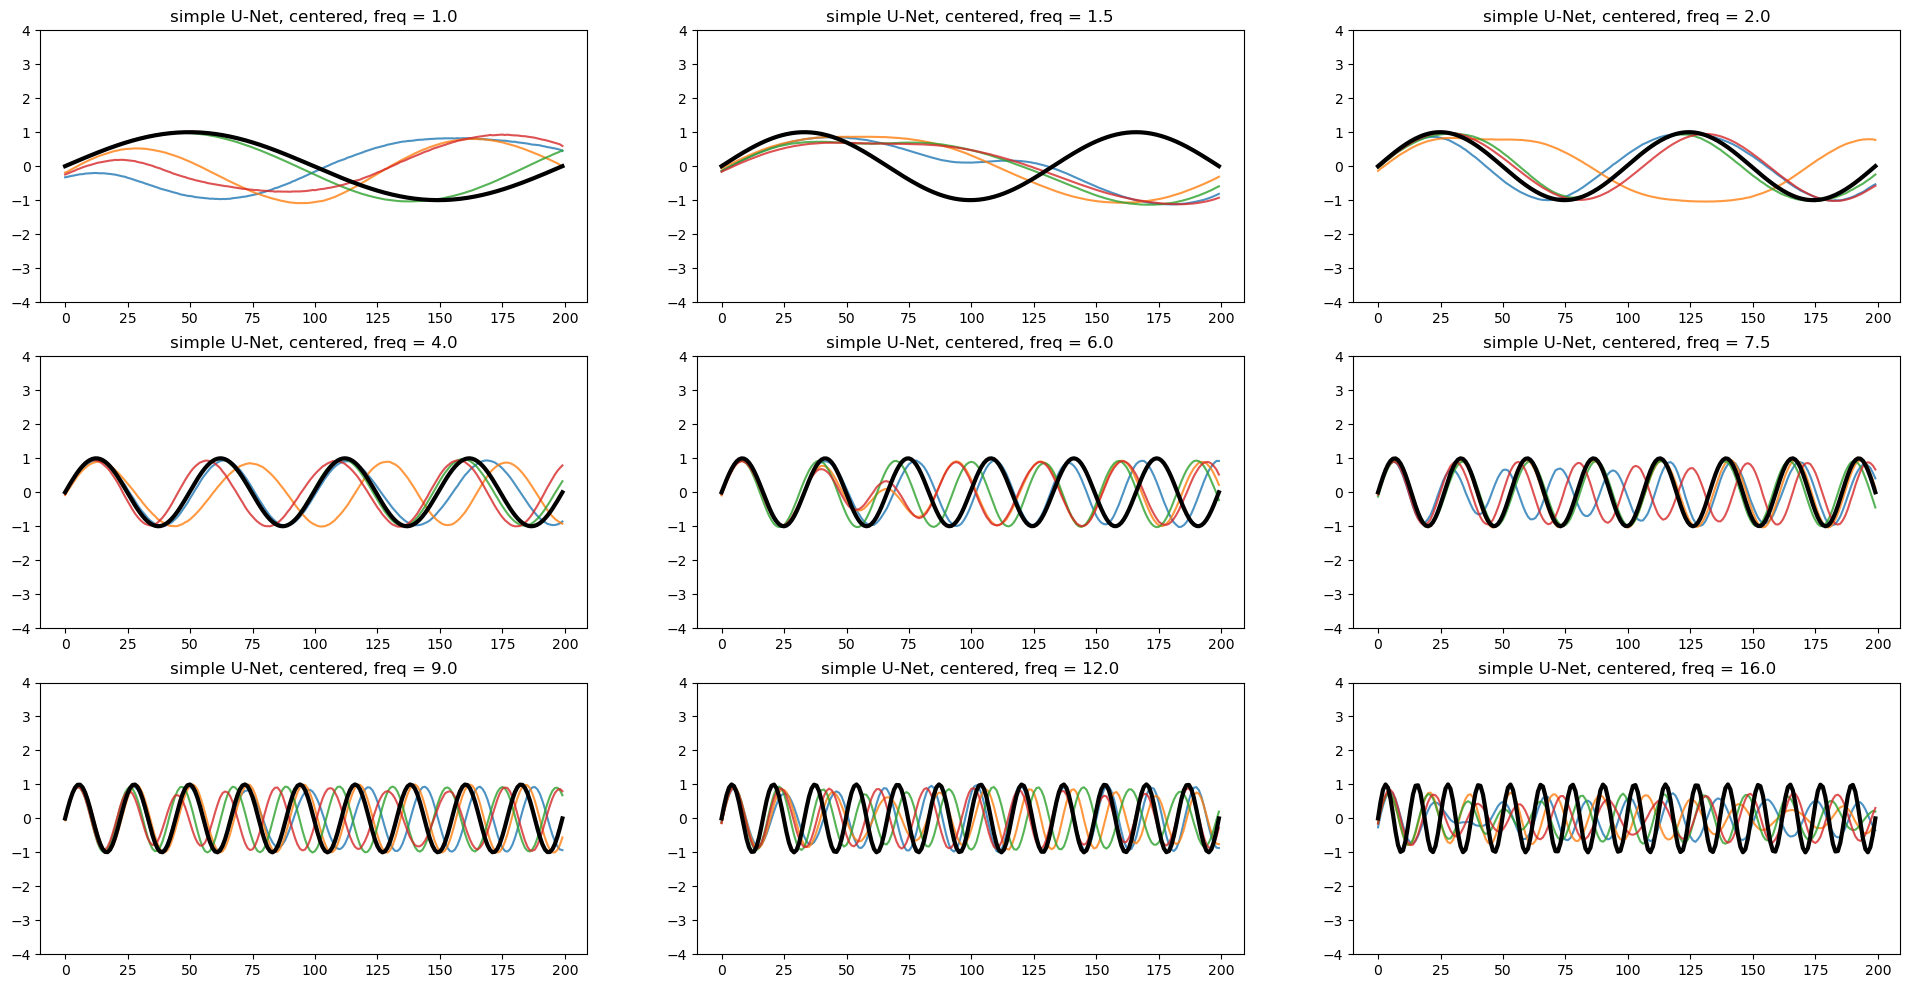

In [15]:
fig, axs = plt.subplots(3, 3, figsize=(24, 12))
axs = axs.ravel()

for ax, generated, truth, freq in zip(axs, generated_list, truth_list, freqs):
    for sample in generated:
        sample = sample[0].detach().cpu()
        sample = sample - sample.mean()
        
        ax.plot(sample, alpha = 0.8)

    ax.plot(truth, linewidth=3, color = "black")
    ax.set_title(f"simple U-Net, centered, freq = {freq}")
    ax.set_ylim(-4, 4)

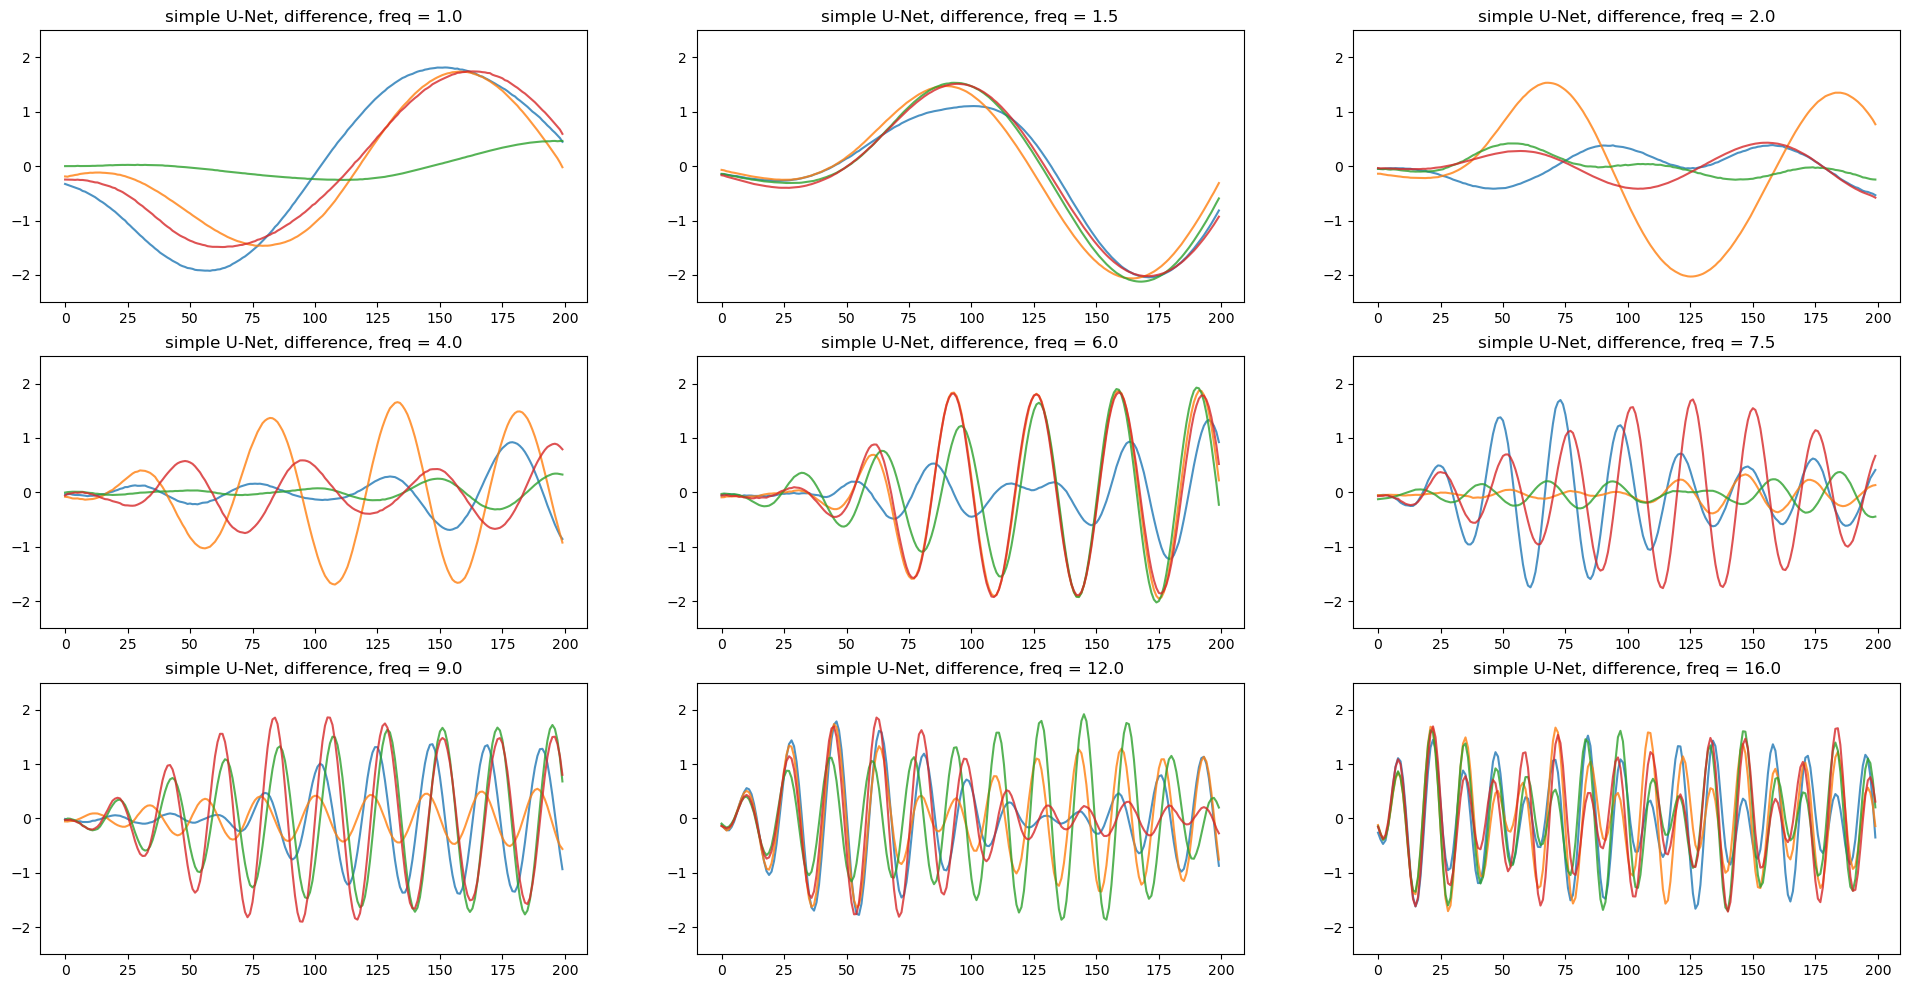

In [16]:
fig, axs = plt.subplots(3, 3, figsize=(24, 12))
axs = axs.ravel()

for ax, generated, truth, freq in zip(axs, generated_list, truth_list, freqs):
    for sample in generated:
        sample = sample[0].detach().cpu()
        sample = sample - sample.mean()
        
        ax.plot(sample - truth, alpha = 0.8)

    ax.set_title(f"simple U-Net, difference, freq = {freq}")
    ax.set_ylim(-2.5, 2.5)